# Exploratory Data Analysis

In [39]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re

In [24]:
data = pd.read_csv("../data/potential_talents_raw.csv")

In [25]:
data.head()

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN


In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          104 non-null    int64  
 1   job_title   104 non-null    object 
 2   location    104 non-null    object 
 3   connection  104 non-null    object 
 4   fit         0 non-null      float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.2+ KB


In [27]:
data['job_title'].nunique()

52

In [28]:
data['job_title'].value_counts()

job_title
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional                 7
Aspiring Human Resources Professional                                                                                    7
Student at Humber College and Aspiring Human Resources Generalist                                                        7
People Development Coordinator at Ryan                                                                                   6
Native English Teacher at EPIK (English Program in Korea)                                                                5
Aspiring Human Resources Specialist                                                                                      5
HR Senior Specialist                                                                                                     5
Student at Chapman University                                                                                            4
SVP, C

In [29]:
data.duplicated(subset=['job_title', 'location', 'connection']).sum()

np.int64(51)

In [30]:
data[data.duplicated(subset=['job_title', 'location', 'connection'])].sort_values(by='job_title')

,id,job_title,location,connection,fit
56,57,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
13,14,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
14,15,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
30,31,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
43,44,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
18,19,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
34,35,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
47,48,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
22,23,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
28,29,Aspiring Human Resources Management student se...,"Houston, Texas Area",500+,NaN


In [31]:
data = data.drop_duplicates(subset=data.columns.difference(['id'])).reset_index(drop=True)

In [68]:
data['job_title'] = data['job_title'].str.replace(r'[^\w\s]', ' ', regex=True).str.lower().str.strip()

In [69]:
data

,id,job_title,location,connection,fit
0,1,2019 c t bauer college of business graduate ...,"Houston, Texas",85,NaN
1,2,native english teacher at epik english progra...,Kanada,500+,NaN
2,3,aspiring human resources professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,people development coordinator at ryan,"Denton, Texas",500+,NaN
4,5,advisory board member at celal bayar university,"İzmir, Türkiye",500+,NaN
5,6,aspiring human resources specialist,Greater New York City Area,1,NaN
6,7,student at humber college and aspiring human r...,Kanada,61,NaN
7,8,hr senior specialist,San Francisco Bay Area,500+,NaN
8,10,seeking human resources hris and generalist po...,Greater Philadelphia Area,500+,NaN
9,11,student at chapman university,"Lake Forest, California",2,NaN


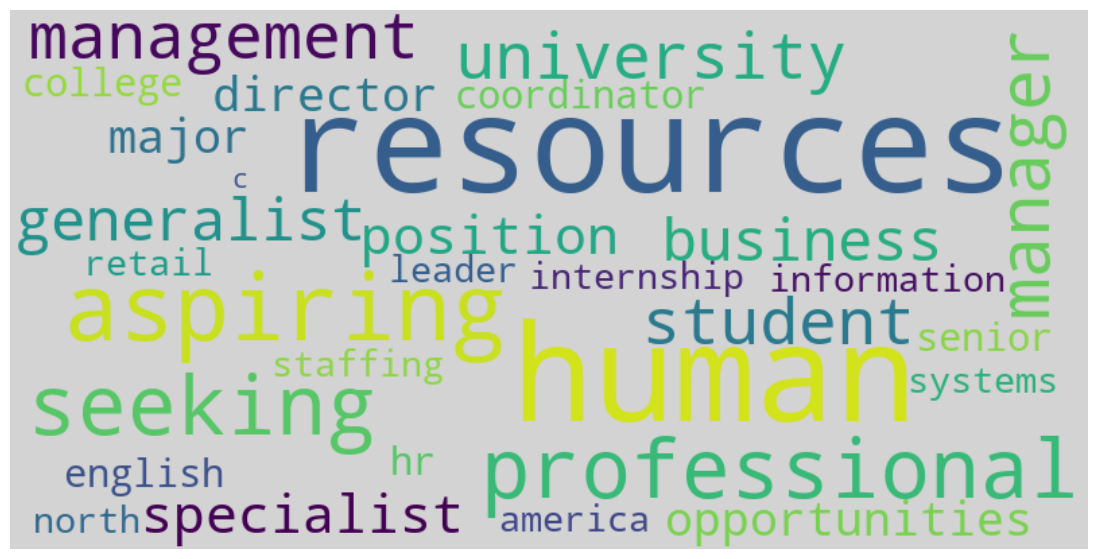

In [72]:
text = " ".join(data['job_title'].astype(str))

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='lightgray',
    max_words=30,
    max_font_size=100,
    colormap='viridis',
    collocations=False
).generate(text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [73]:
data.to_csv("../data/potential_talents_cleaned.csv", index=False)